# Rio 2016: do bigger delegations win more medals?

**Research question.** Among the countries that competed at the 2016 Rio Olympics,
how strongly does the size of a delegation relate to the number of medals won,
and which countries are the most efficient per athlete?

**Data.** `data/olympia2016_athletes.csv`, one row per athlete (11,538 rows, 207
countries). The medal columns are *athlete-level*: a team gold is recorded once
for every member of the squad, not once per event — this matters for the
limitation discussed at the end.

In [2]:
import os

import pandas as pd
import matplotlib.pyplot as plt

DATA = os.path.join('data', 'olympia2016_athletes.csv')
if not os.path.exists(DATA):
    raise FileNotFoundError(
        'Put olympia2016_athletes.csv into data/ - see data/README.md for the schema')

df = pd.read_csv(DATA)
print('rows, columns:', df.shape)
df.head()

rows, columns: (11538, 11)


,id,name,nationality,sex,dob,height,weight,sport,gold,silver,bronze
0,736041664,A Jesus Garcia,ESP,male,10/17/69,1.72,64.0,athletics,0,0,0
1,532037425,A Lam Shin,KOR,female,9/23/86,1.68,56.0,fencing,0,0,0
2,435962603,Aaron Brown,CAN,male,5/27/92,1.98,79.0,athletics,0,0,1
3,521041435,Aaron Cook,MDA,male,1/2/91,1.83,80.0,taekwondo,0,0,0
4,33922579,Aaron Gate,NZL,male,11/26/90,1.81,71.0,cycling,0,0,0


## One row per country

Count the athletes and sum the medal columns for every nationality, then compute
a simple efficiency metric.

In [3]:
countries = df.groupby('nationality', as_index=False).agg(
    athletes=('id', 'count'),
    gold=('gold', 'sum'),
    silver=('silver', 'sum'),
    bronze=('bronze', 'sum'))

countries['medals'] = countries['gold'] + countries['silver'] + countries['bronze']
countries['efficiency'] = countries['medals'] / countries['athletes']

print('countries in the dataset      :', len(countries))
print('countries with at least 1 medal:', int((countries['medals'] > 0).sum()))
print('medals per athlete overall    :',
      round(countries['medals'].sum() / countries['athletes'].sum(), 3))
countries.sort_values('medals', ascending=False).head(10)

countries in the dataset      : 207
countries with at least 1 medal: 87
medals per athlete overall    : 0.176


,nationality,athletes,gold,silver,bronze,medals,efficiency
198,USA,567,139,54,71,264,0.465608
72,GER,441,49,44,67,160,0.362812
68,GBR,374,64,55,26,145,0.387701
159,RUS,286,52,29,34,115,0.402098
38,CHN,404,46,30,37,113,0.279703
64,FRA,410,20,54,21,95,0.231707
10,AUS,431,23,34,25,82,0.190255
93,ITA,312,8,40,24,72,0.230769
33,CAN,321,4,4,61,69,0.214953
97,JPN,346,17,13,35,65,0.187861


## Finding 1 — delegation size explains most of the medal table

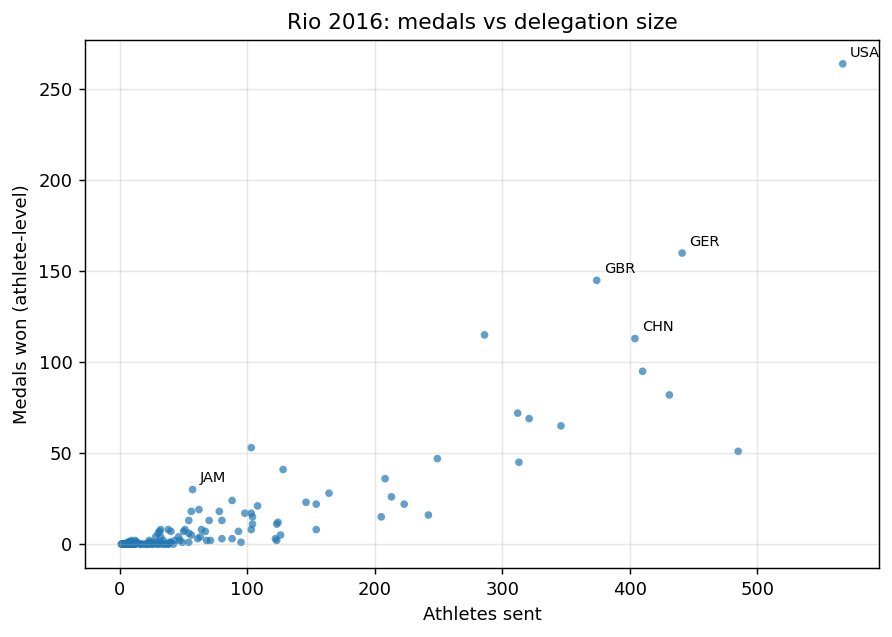

corr(athletes, medals) = 0.869
corr(athletes, gold)   = 0.758


In [4]:
os.makedirs('figures', exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 5), dpi=130)
ax.scatter(countries['athletes'], countries['medals'], s=18, alpha=0.7,
           edgecolor='none')
for code in ['USA', 'GER', 'GBR', 'CHN', 'JAM']:
    row = countries[countries['nationality'] == code].iloc[0]
    ax.annotate(code, (row['athletes'], row['medals']),
                textcoords='offset points', xytext=(4, 4), fontsize=8)
ax.set_xlabel('Athletes sent')
ax.set_ylabel('Medals won (athlete-level)')
ax.set_title('Rio 2016: medals vs delegation size')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('figures/medals_vs_athletes.png')
plt.show()

print('corr(athletes, medals) =',
      round(countries['athletes'].corr(countries['medals']), 3))
print('corr(athletes, gold)   =',
      round(countries['athletes'].corr(countries['gold']), 3))

The same scatter as an interactive figure: hover a point to read the country
code, the number of athletes and the medal split.

In [5]:
from bokeh.io import output_notebook
from bokeh.models import ColumnDataSource
from bokeh.plotting import figure, show

output_notebook()

source = ColumnDataSource(
    countries[['nationality', 'athletes', 'medals', 'gold', 'efficiency']])

plot = figure(title='Rio 2016: medals vs athletes (hover for details)',
              x_axis_label='Athletes sent',
              y_axis_label='Medals won',
              width=650, height=420,
              tooltips=[('Country', '@nationality'),
                        ('Athletes', '@athletes'),
                        ('Medals', '@medals'),
                        ('Gold', '@gold'),
                        ('Medals per athlete', '@efficiency{0.000}')])
plot.scatter('athletes', 'medals', size=6, alpha=0.6, source=source)
show(plot)

Loading BokehJS ...

## Finding 2 — size is not the whole story

Restrict to countries with at least 20 athletes (so that one lucky medal for a
three-person delegation cannot top the chart) and rank by medals per athlete.

nationality  athletes  medals  efficiency
        JAM        57      30    0.526316
        SRB       103      53    0.514563
        USA       567     264    0.465608
        RUS       286     115    0.402098
        GBR       374     145    0.387701
        GER       441     160    0.362812
        AZE        56      18    0.321429
        DEN       128      41    0.320312
        NOR        62      19    0.306452
        CHN       404     113    0.279703
        CRO        88      24    0.272727
        MAS        32       8    0.250000
        FIJ        54      13    0.240741
        FRA       410      95    0.231707
        ITA       312      72    0.230769


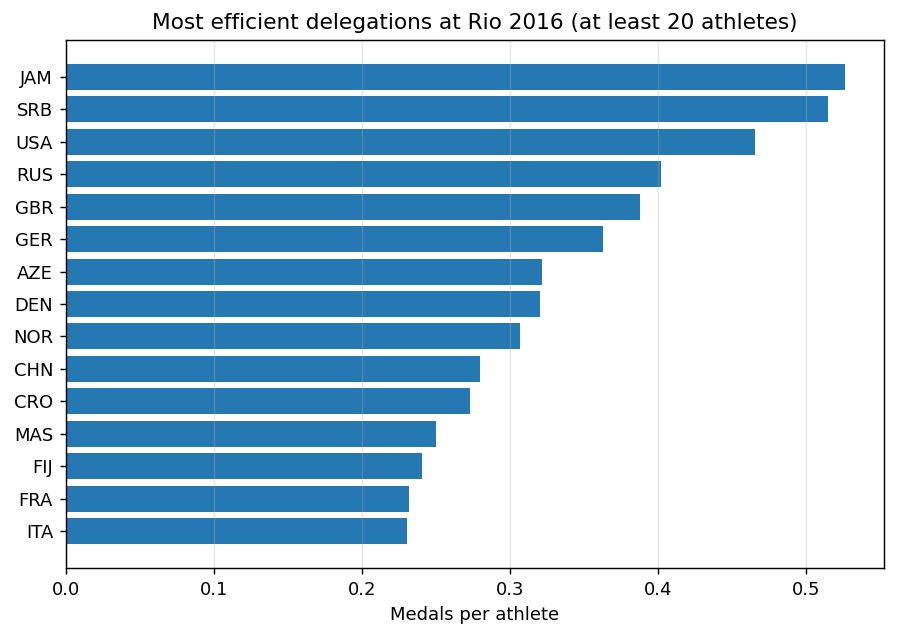

In [6]:
big = countries[countries['athletes'] >= 20]
top = big.sort_values('efficiency', ascending=False).head(15)
print(top[['nationality', 'athletes', 'medals', 'efficiency']].to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5), dpi=130)
ax.barh(top['nationality'][::-1], top['efficiency'][::-1], color='#2678b2')
ax.set_xlabel('Medals per athlete')
ax.set_title('Most efficient delegations at Rio 2016 (at least 20 athletes)')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig('figures/efficiency_top15.png')
plt.show()

## Findings

1. **Delegation size explains most of the medal table.** Across the 207 nations
   that competed, `corr(athletes, medals) = 0.869` (and `0.758` against gold
   only). The relationship is close to linear through the middle of the
   distribution and flattens at the very top.
2. **Medals are extremely concentrated.** Only **87 of 207** countries won
   anything; the top eight are USA (264), GER (160), GBR (145), RUS (115),
   CHN (113), FRA (95), AUS (82) and ITA (72) athlete-medal entries.
3. **Efficiency separates the small, sharp delegations from the big ones.**
   With at least 20 athletes, Jamaica leads at **0.526 medals per athlete**
   (57 athletes, 30 medals), ahead of Serbia (0.515), the USA (0.466), Russia
   (0.402) and Great Britain (0.388), against an overall rate of 0.176.

## Limitation

The medal columns are counted per **athlete**, so a team gold (basketball,
relay, football) is recorded once for each squad member: the USA shows 139
"gold" here against 46 gold medals in the official table. Team-sport-heavy
nations therefore look both more decorated and more efficient than they are.
Fixing this needs event identifiers, which this dataset does not contain — the
next step for the project.